In [11]:
from pydantic import BaseModel
from langgraph.graph import StateGraph, START, END

In [12]:
class GreetState(BaseModel):
    message: str = ""

In [13]:
graph = StateGraph(GreetState)

In [14]:
def Greet(state:GreetState):
    state.message=f"{state.message}Hello, welcome to the state graph!"
    return state



def upperCase(state:GreetState):
    state.message=state.message.upper()
    return state


In [15]:
graph.add_node("greet1",Greet)
graph.add_node("upperCase1",upperCase)

In [16]:
graph.add_edge(START, "greet1")
graph.add_edge("greet1", "upperCase1")
graph.add_edge("upperCase1", END)

In [17]:
finalGraph = graph.compile()
res = finalGraph.invoke({"message":"yoo mannn!"})
res

{'message': 'YOO MANNN!HELLO, WELCOME TO THE STATE GRAPH!'}

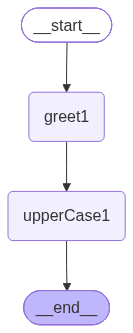

In [18]:
from IPython.display import Image
Image(finalGraph.get_graph().draw_mermaid_png())
